In [1]:
# Task 1: Image Restoration and Segmentation

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

print("All libraries imported successfully!")

print("NumPy Version:", np.__version__)
print("OpenCV Version:", cv2.__version__)

All libraries imported successfully!
NumPy Version: 1.26.4
OpenCV Version: 4.10.0


In [3]:
# Define project directories

PROJECT_DIR = Path.cwd()

DATASET_DIR = PROJECT_DIR / "dataset"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task1_restoration"

# Create output directories
DATASET_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Directory:", PROJECT_DIR)
print("Dataset Directory:", DATASET_DIR)
print("Output Directory:", OUTPUT_DIR)

print("\nFolders created successfully!")

Project Directory: C:\Users\ahada\CV_assignment3
Dataset Directory: C:\Users\ahada\CV_assignment3\dataset
Output Directory: C:\Users\ahada\CV_assignment3\outputs\task1_restoration

Folders created successfully!


Image loaded successfully!
Image dimensions: (4032, 3024, 3)


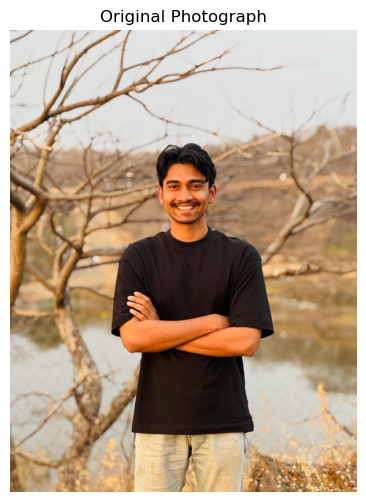

True

In [5]:
# Load original photograph

image_path = DATASET_DIR / "original_photo.jpg"

original_bgr = cv2.imread(str(image_path))

if original_bgr is None:
    raise FileNotFoundError(
        "original_photo.jpg not found inside dataset folder!"
    )

# Convert BGR to RGB
original = cv2.cvtColor(
    original_bgr,
    cv2.COLOR_BGR2RGB
)

# Convert to grayscale
gray = cv2.cvtColor(
    original_bgr,
    cv2.COLOR_BGR2GRAY
)

print("Image loaded successfully!")
print("Image dimensions:", original.shape)

# Display original image
plt.figure(figsize=(8, 6))
plt.imshow(original)
plt.title("Original Photograph")
plt.axis("off")
plt.show()

# Save original image
cv2.imwrite(
    str(OUTPUT_DIR / "original_photo.png"),
    original_bgr
)

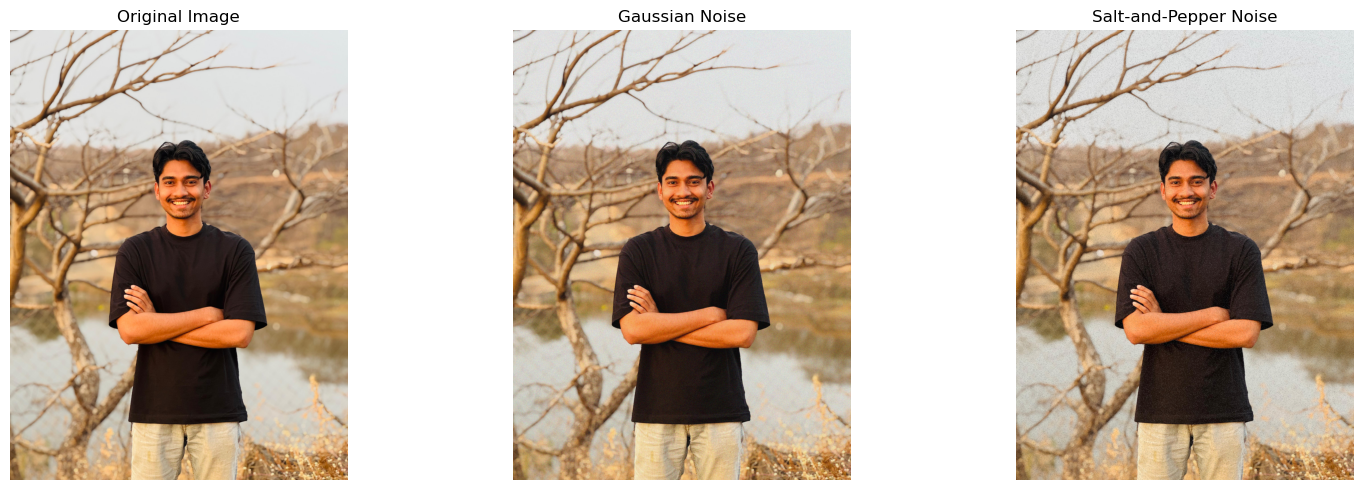

Both noisy images generated and saved successfully!


In [7]:
# Task 1A: Adding Noise to Original Image

# Set random seed for reproducibility
np.random.seed(42)

# 1. Gaussian Noise
gaussian_noise = np.random.normal(
    0, 25, original.shape
)

noisy_gaussian = np.clip(
    original.astype(np.float32) + gaussian_noise,
    0, 255
).astype(np.uint8)


# 2. Salt-and-Pepper Noise
noisy_sp = original.copy()

random_values = np.random.random(original.shape[:2])

salt_mask = random_values < 0.025
pepper_mask = (
    (random_values >= 0.025) &
    (random_values < 0.05)
)

noisy_sp[salt_mask] = [255, 255, 255]
noisy_sp[pepper_mask] = [0, 0, 0]


# Display all images
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(noisy_gaussian)
axes[1].set_title("Gaussian Noise")

axes[2].imshow(noisy_sp)
axes[2].set_title("Salt-and-Pepper Noise")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# Save images
cv2.imwrite(
    str(OUTPUT_DIR / "gaussian_noise.png"),
    cv2.cvtColor(noisy_gaussian, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "salt_pepper_noise.png"),
    cv2.cvtColor(noisy_sp, cv2.COLOR_RGB2BGR)
)

print("Both noisy images generated and saved successfully!")

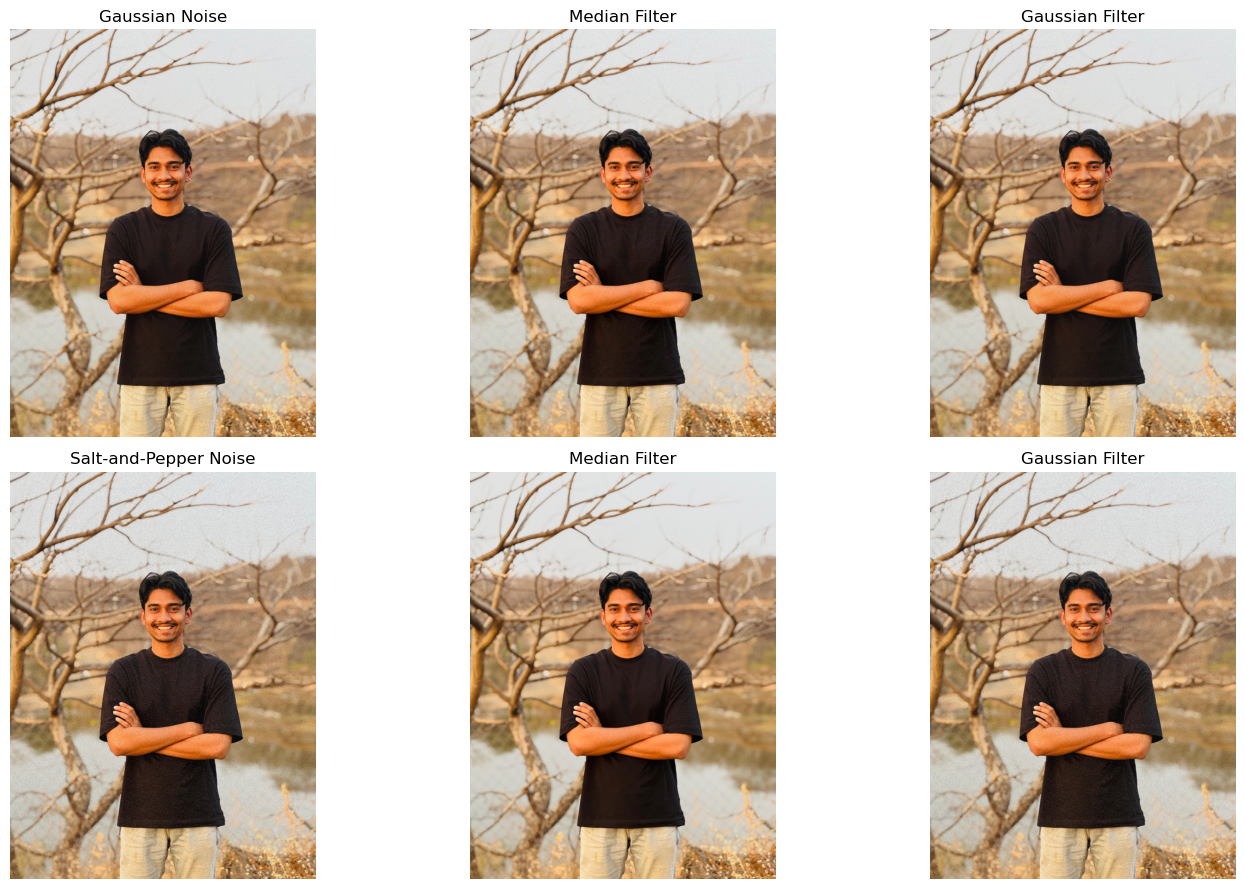

Image restoration completed successfully!


In [9]:
# Task 1A: Image Restoration using Filters

# 1. Median Filtering
median_gaussian = cv2.medianBlur(noisy_gaussian, 5)
median_sp = cv2.medianBlur(noisy_sp, 5)


# 2. Gaussian Filtering
gaussian_filtered = cv2.GaussianBlur(
    noisy_gaussian, (5, 5), 0
)

gaussian_filtered_sp = cv2.GaussianBlur(
    noisy_sp, (5, 5), 0
)


# Display restoration results
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

images = [
    (noisy_gaussian, "Gaussian Noise"),
    (median_gaussian, "Median Filter"),
    (gaussian_filtered, "Gaussian Filter"),

    (noisy_sp, "Salt-and-Pepper Noise"),
    (median_sp, "Median Filter"),
    (gaussian_filtered_sp, "Gaussian Filter")
]

for ax, (img, title) in zip(axes.flat, images):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Save restored images
cv2.imwrite(
    str(OUTPUT_DIR / "median_gaussian.png"),
    cv2.cvtColor(median_gaussian, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "median_salt_pepper.png"),
    cv2.cvtColor(median_sp, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "gaussian_filtered.png"),
    cv2.cvtColor(gaussian_filtered, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "gaussian_filtered_salt_pepper.png"),
    cv2.cvtColor(gaussian_filtered_sp, cv2.COLOR_RGB2BGR)
)

print("Image restoration completed successfully!")

In [11]:
# Task 1A: Calculate PSNR and SSIM

def calculate_metrics(original, processed):

    psnr = peak_signal_noise_ratio(
        original,
        processed,
        data_range=255
    )

    ssim = structural_similarity(
        original,
        processed,
        channel_axis=2,
        data_range=255
    )

    return psnr, ssim


# Store all images for comparison
metric_images = {
    "Gaussian Noise": noisy_gaussian,
    "Gaussian + Median Filter": median_gaussian,
    "Gaussian + Gaussian Filter": gaussian_filtered,
    "Salt-and-Pepper Noise": noisy_sp,
    "Salt-and-Pepper + Median Filter": median_sp,
    "Salt-and-Pepper + Gaussian Filter": gaussian_filtered_sp
}


# Calculate metrics
comparison_data = []

for name, img in metric_images.items():

    psnr, ssim = calculate_metrics(original, img)

    comparison_data.append({
        "Technique": name,
        "PSNR (dB)": round(psnr, 2),
        "SSIM": round(ssim, 4)
    })


# Create comparison table
comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

,Technique,PSNR (dB),SSIM
0,Gaussian Noise,20.58,0.1375
1,Gaussian + Median Filter,31.90,0.7152
2,Gaussian + Gaussian Filter,31.38,0.6814
3,Salt-and-Pepper Noise,17.79,0.2339
4,Salt-and-Pepper + Median Filter,44.83,0.9859
5,Salt-and-Pepper + Gaussian Filter,28.34,0.5899


In [13]:
# Save comparison results as CSV

comparison_df.to_csv(
    OUTPUT_DIR / "restoration_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

Comparison table saved successfully!


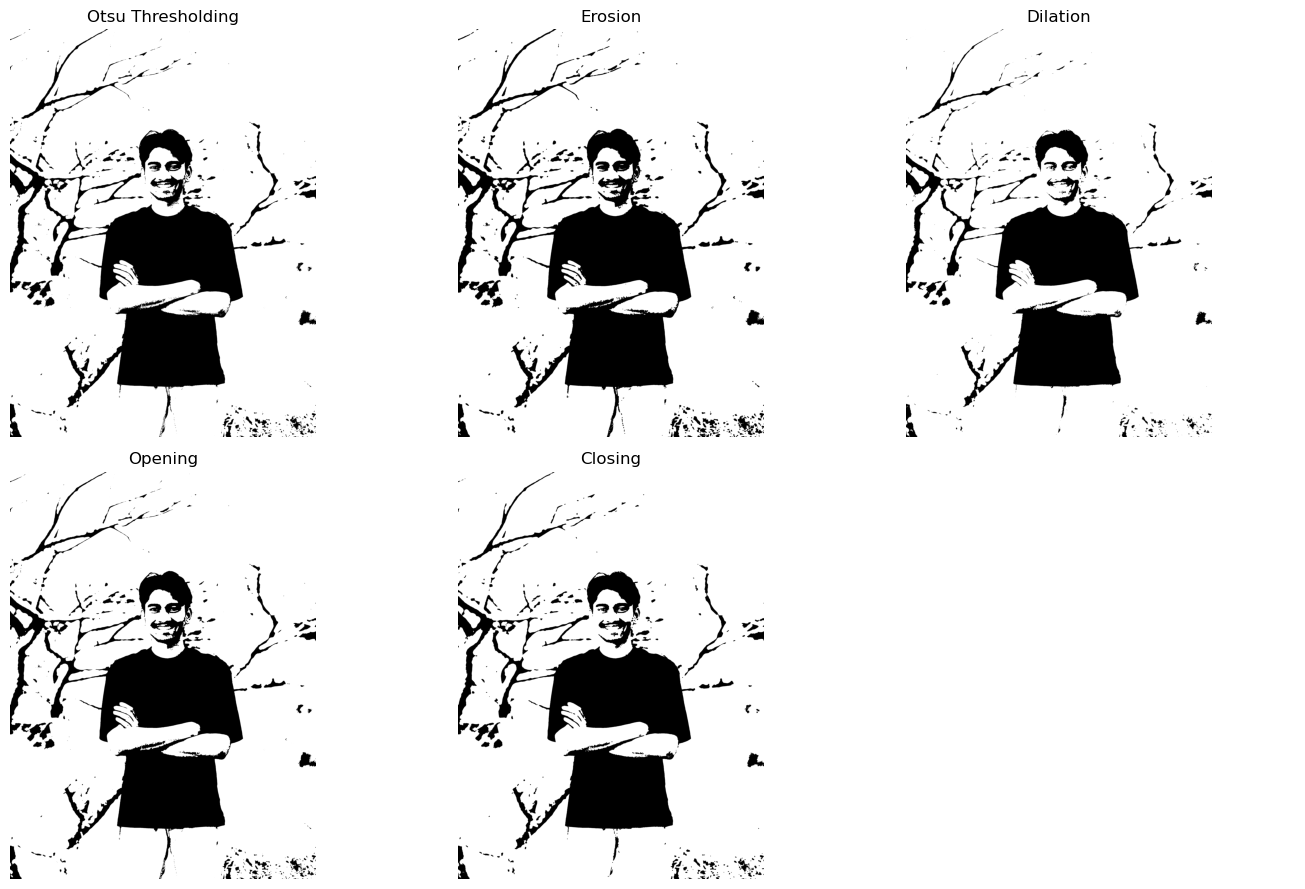

Morphological processing completed!
Otsu threshold value: 114.0


In [15]:
# Task 1B: Morphological Processing

# Convert original image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Apply Otsu thresholding
threshold_value, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Create structuring element
kernel = np.ones((5, 5), np.uint8)

# Apply morphological operations
erosion = cv2.erode(binary, kernel, iterations=1)

dilation = cv2.dilate(binary, kernel, iterations=1)

opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel
)

closing = cv2.morphologyEx(
    binary, cv2.MORPH_CLOSE, kernel
)

# Display results
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

results = [
    (binary, "Otsu Thresholding"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
]

for ax, (img, title) in zip(axes.flat, results):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

# Save results
morph_results = {
    "binary_threshold.png": binary,
    "erosion.png": erosion,
    "dilation.png": dilation,
    "opening.png": opening,
    "closing.png": closing
}

for filename, img in morph_results.items():
    cv2.imwrite(str(OUTPUT_DIR / filename), img)

print("Morphological processing completed!")
print("Otsu threshold value:", threshold_value)

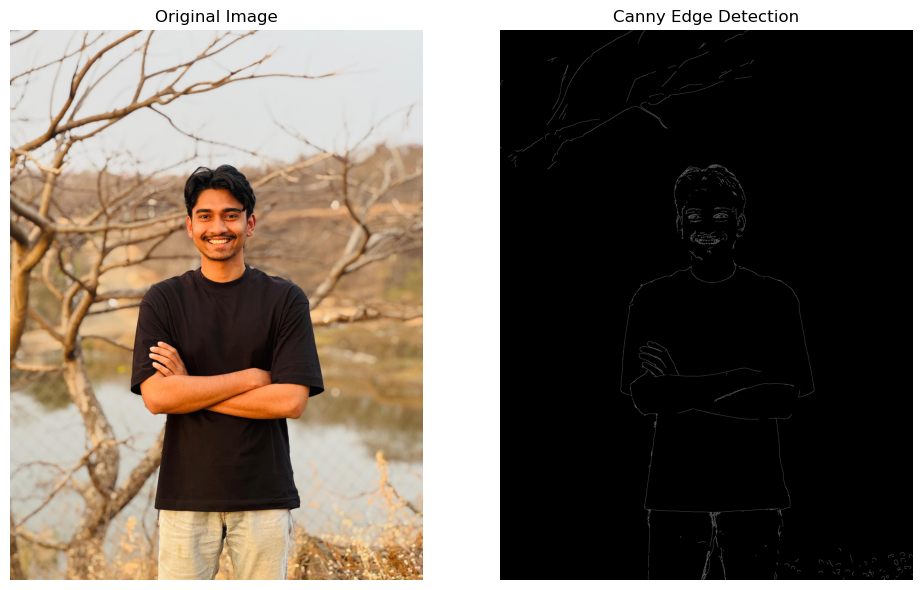

Canny edge detection completed!


In [17]:
# Canny Edge Detection

edges = cv2.Canny(
    gray,
    threshold1=100,
    threshold2=200
)

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save edge image
cv2.imwrite(
    str(OUTPUT_DIR / "canny_edges.png"),
    edges
)

print("Canny edge detection completed!")

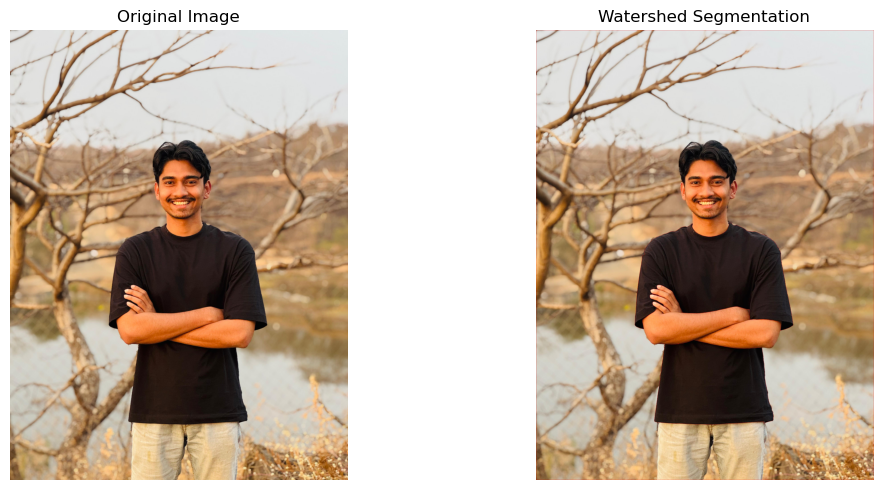

True

In [19]:
# Convert the original image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Apply Otsu thresholding
_, watershed_binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Ensure foreground objects are white
if np.mean(watershed_binary == 255) > 0.5:
    watershed_binary = cv2.bitwise_not(watershed_binary)

# Noise removal
kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    watershed_binary, cv2.MORPH_OPEN, kernel, iterations=2
)

# Identify sure background
sure_background = cv2.dilate(opening_ws, kernel, iterations=3)

# Distance transform to identify sure foreground
distance = cv2.distanceTransform(opening_ws, cv2.DIST_L2, 5)

_, sure_foreground = cv2.threshold(
    distance, 0.4 * distance.max(), 255, 0
)

sure_foreground = np.uint8(sure_foreground)

# Identify unknown region
unknown = cv2.subtract(sure_background, sure_foreground)

# Create markers
_, markers = cv2.connectedComponents(sure_foreground)
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
watershed_result = original.copy()
markers = cv2.watershed(
    cv2.cvtColor(original, cv2.COLOR_RGB2BGR), markers
)

# Mark boundaries in red
watershed_result[markers == -1] = [255, 0, 0]

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(watershed_result)
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
cv2.imwrite(
    str(OUTPUT_DIR / "watershed_segmentation.png"),
    cv2.cvtColor(watershed_result, cv2.COLOR_RGB2BGR)
)